In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score , confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import joblib


In [ ]:
df = pd.read_csv("/content/random_forest_dataset.csv")

In [ ]:
df.head()

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,target
0,5.340994,-2.339324,-0.205364,1.619784,-3.908994,-0.150075,-1.125429,-2.546089,-1.642008,1.083061,1.270379,-1.249822,1.485236,4.776931,-2.742463,2.586550,0.267504,4.911893,1.135798,6.843646,0
1,-9.698673,1.879274,5.136846,-2.060767,-0.996011,3.181908,1.940531,0.759808,6.646273,-4.775781,-2.959434,7.393315,-1.948952,-5.482224,-1.801650,0.713386,1.217702,1.206695,-1.435281,-0.923605,1
2,0.154577,-0.849201,1.276473,0.029095,-2.073553,-0.668501,-1.035186,-0.892474,-1.203695,1.230525,-1.842747,-1.861831,0.324801,3.908175,3.335574,0.187837,1.905351,-0.208369,2.347017,-1.740545,1
3,7.486360,-2.355128,0.344523,-0.363427,0.266045,-0.587793,-1.583515,0.073917,-6.011549,-0.310638,0.462651,2.626559,2.787696,7.939736,-3.253834,1.270556,2.757290,4.832000,3.416729,4.473270,0
4,8.800388,-3.933211,-2.528425,-1.688015,6.045728,-3.105363,0.164567,-0.539202,-8.814229,0.575969,5.205830,1.432271,2.215008,5.963390,-1.552177,-1.327727,6.476104,2.762324,4.239386,2.894308,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   feature_0   1000 non-null   float64
 1   feature_1   1000 non-null   float64
 2   feature_2   1000 non-null   float64
 3   feature_3   1000 non-null   float64
 4   feature_4   1000 non-null   float64
 5   feature_5   1000 non-null   float64
 6   feature_6   1000 non-null   float64
 7   feature_7   1000 non-null   float64
 8   feature_8   1000 non-null   float64
 9   feature_9   1000 non-null   float64
 10  feature_10  1000 non-null   float64
 11  feature_11  1000 non-null   float64
 12  feature_12  1000 non-null   float64
 13  feature_13  1000 non-null   float64
 14  feature_14  1000 non-null   float64
 15  feature_15  1000 non-null   float64
 16  feature_16  1000 non-null   float64
 17  feature_17  1000 non-null   float64
 18  feature_18  1000 non-null   float64
 19  feature_19  1000 non-null   

In [ ]:
df.isnull().sum()

,0
feature_0,0
feature_1,0
feature_2,0
feature_3,0
feature_4,0
feature_5,0
feature_6,0
feature_7,0
feature_8,0
feature_9,0


In [ ]:
## Separate feature and target

X = df.drop("target", axis = 1)
y = df["target"]

<Axes: xlabel='target', ylabel='count'>

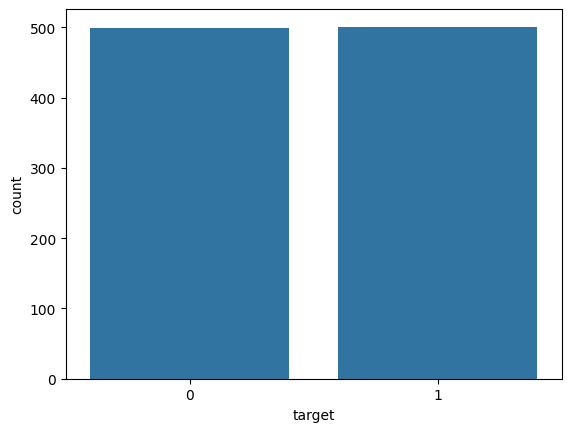

In [ ]:
sns.countplot(x = 'target', data = df)

In [ ]:
## Scaling

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Update DataFrame
X = X_scaled

In [ ]:
## Train- test split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state = 42)

In [ ]:
print(f" trainng set size: {X_train.shape}")

 trainng set size: (800, 20)


In [ ]:
print(f" testing set size: {X_test.shape}")

 testing set size: (200, 20)


In [ ]:
## model traning

In [ ]:
rf = RandomForestClassifier(n_estimators=100, random_state= 42)

rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
## Model EValuation

y_pred = rf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

In [ ]:
print(f'Accuracy: {accuracy:.4f}')
print(f'F1 Score: {f1:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')

Accuracy: 0.9850
F1 Score: 0.9860
Precision: 0.9815
Recall: 0.9907
